In [1]:
import torch
import math
from torch.distributions.multivariate_normal import MultivariateNormal
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
def fftfreq_1d(N, L, device=None, dtype=torch.float32):
    # frequencies in cycles per length -> convert to wavenumbers 2π/L
    k = torch.fft.fftfreq(N, d=L/N, device=device)
    return 2*math.pi*k.to(dtype=dtype)

@torch.no_grad()
def etdrk4_coeffs(Lop, dt, M=32):
    """
    Lop: (N,) complex tensor of linear operator eigenvalues in Fourier space.
    Returns ETDRK4 coeffs arrays (all (N,) complex).
    """
    device = Lop.device
    cdtype = Lop.dtype
    # use a real dtype for arange/angles
    rdtype = torch.float32 if cdtype == torch.complex64 else torch.float64

    j = torch.arange(1, M+1, device=device, dtype=rdtype)  # real
    angles = math.pi * (j - 0.5) / M                       # real
    r = torch.exp(1j * angles.to(cdtype))                  # (M,) complex

    LR = dt * Lop[:, None] + r[None, :]                    # (N,M) complex

    E  = torch.exp(dt * Lop)                               # (N,)
    E2 = torch.exp(dt * Lop / 2)                           # (N,)

    Q  = dt * torch.mean((torch.exp(LR/2) - 1) / LR, dim=1)
    f1 = dt * torch.mean((-4 - LR + torch.exp(LR)*(4 - 3*LR + LR**2)) / (LR**3), dim=1)
    f2 = dt * torch.mean(( 2 + LR + torch.exp(LR)*(-2 + LR)) / (LR**3), dim=1)
    f3 = dt * torch.mean((-4 - 3*LR - LR**2 + torch.exp(LR)*(4 - LR)) / (LR**3), dim=1)

    return E, E2, Q, f1, f2, f3

In [3]:
@torch.no_grad()
def ks_rhs_nonlinear(u, k):
    """
    Nonlinear term N(u) in Fourier space for KS:
      u_t = (k^2 - k^4) u_hat + N_hat
      N_hat = -0.5*i*k*FFT(u^2)
    u: (B,N) real
    k: (N,) real wavenumbers
    returns N_hat: (B,N) complex
    """
    u2 = u*u
    u2_hat = torch.fft.fft(u2, dim=-1)
    return -0.5j * k[None, :].to(u2_hat.dtype) * u2_hat

@torch.no_grad()
def integrate_ks_etdrk4(u0, L=22.0, dt=0.25, steps=2000, save_every=1, dealias=True):
    """
    u0: (B,N) real initial condition on periodic domain length L.
    Returns traj: (T,B,N) real, where T = steps//save_every + 1
    """
    device = u0.device
    dtype = torch.float32 if u0.dtype in (torch.float16, torch.bfloat16) else u0.dtype

    B, N = u0.shape
    k = fftfreq_1d(N, L, device=device, dtype=dtype)  # (N,)
    k_c = k.to(torch.complex64 if dtype == torch.float32 else torch.complex128)

    # Linear operator in Fourier: (k^2 - k^4)
    Lop = (k**2 - k**4).to(k_c.dtype)  # (N,) complex
    E, E2, Q, f1, f2, f3 = etdrk4_coeffs(Lop, dt)

    # 2/3 de-aliasing mask
    if dealias:
        k_indices = torch.fft.fftfreq(N, d=1.0, device=device)
        cutoff = (N//3) / N
        mask = (k_indices.abs() <= cutoff).to(k_c.dtype)
    else:
        mask = torch.ones(N, device=device, dtype=k_c.dtype)

    # initial state in Fourier
    u_hat = torch.fft.fft(u0.to(dtype), dim=-1).to(k_c.dtype)

    Tsave = steps // save_every + 1
    traj = torch.empty(Tsave, B, N, device=device, dtype=dtype)
    traj[0] = u0.to(dtype)
    si = 1

    for n in range(1, steps+1):
        u = torch.fft.ifft(u_hat, dim=-1).real  # (B,N)

        Nv = ks_rhs_nonlinear(u, k) * mask[None, :]
        a_hat = E2[None,:]*u_hat + Q[None,:]*Nv

        a = torch.fft.ifft(a_hat, dim=-1).real
        Na = ks_rhs_nonlinear(a, k) * mask[None,:]
        b_hat = E2[None,:]*u_hat + Q[None,:]*Na

        b = torch.fft.ifft(b_hat, dim=-1).real
        Nb = ks_rhs_nonlinear(b, k) * mask[None,:]
        c_hat = E2[None,:]*a_hat + Q[None,:]*(2*Nb - Nv)

        c = torch.fft.ifft(c_hat, dim=-1).real
        Nc = ks_rhs_nonlinear(c, k) * mask[None,:]

        u_hat = E[None,:]*u_hat + f1[None,:]*Nv + 2*f2[None,:]*(Na+Nb) + f3[None,:]*Nc
        u_hat = u_hat * mask[None,:]

        if n % save_every == 0:
            traj[si] = torch.fft.ifft(u_hat, dim=-1).real
            si += 1

    return traj

In [4]:
@torch.no_grad()
def ic_low_mode_random(B, N, L, n_modes=8, amp=1.0, device="cpu", dtype=torch.float32):
    """
    Real-valued smooth random Fourier series with n_modes active.
    Good for KS.
    """
    x = torch.linspace(0, L, N, device=device, dtype=dtype, requires_grad=False)[:-1]
    x = torch.cat([x, x[:1]])  # length N, periodic endpoint duplication
    x = x[:N]
    u = torch.zeros(B, N, device=device, dtype=dtype)
    for m in range(1, n_modes+1):
        a = torch.randn(B, 1, device=device, dtype=dtype)
        b = torch.randn(B, 1, device=device, dtype=dtype)
        u = u + (amp/m) * (a*torch.cos(2*math.pi*m*x/L) + b*torch.sin(2*math.pi*m*x/L))
    # remove mean
    u = u - u.mean(dim=1, keepdim=True)
    return u

@torch.no_grad()
def ic_localized_bumps(B, N, L, n_bumps=3, amp=1.0, width=0.5, device="cpu", dtype=torch.float32):
    """
    Sum of a few Gaussians (wrapped on periodic domain). Good for KS.
    """
    x = torch.linspace(0, L, N, device=device, dtype=dtype, requires_grad=False)
    u = torch.zeros(B, N, device=device, dtype=dtype)
    for _ in range(n_bumps):
        c = torch.rand(B, 1, device=device, dtype=dtype) * L
        a = torch.randn(B, 1, device=device, dtype=dtype) * amp
        # periodic distance
        dx = torch.minimum((x[None,:]-c).abs(), L-(x[None,:]-c).abs())
        u = u + a * torch.exp(-(dx**2)/(2*width*width))
    u = u - u.mean(dim=1, keepdim=True)
    return u

@torch.no_grad()
def ic_cgl_plane_waves(B, N, L, n_waves=4, amp=1.0, noise=0.05, device="cpu", dtype=torch.complex64):
    """
    Complex superposition of a few plane waves with random phases + small noise.
    Good for CGL.
    """
    x = torch.linspace(0, L, N, device=device, dtype=torch.float32, requires_grad=False)
    A = torch.zeros(B, N, device=device, dtype=dtype)
    for m in range(1, n_waves+1):
        phase = 2*math.pi*torch.rand(B, 1, device=device)  # random phase
        k = m * 2*math.pi / L
        A = A + (amp/m) * torch.exp(1j*(k*x[None,:] + phase))
    # add small complex noise
    A = A + noise*(torch.randn(B, N, device=device) + 1j*torch.randn(B, N, device=device)).to(dtype)
    return A

@torch.no_grad()
def ic_cgl_random_smooth(B, N, L, n_modes=10, amp=1.0, device="cpu", dtype=torch.complex64):
    """
    Complex smooth random Fourier series. Good for CGL.
    """
    x = torch.linspace(0, L, N, device=device, dtype=torch.float32, requires_grad=False)
    A = torch.zeros(B, N, device=device, dtype=dtype)
    for m in range(1, n_modes+1):
        a = torch.randn(B, 1, device=device) + 1j*torch.randn(B, 1, device=device)
        A = A + (amp/m) * a.to(dtype) * torch.exp(1j*(2*math.pi*m*x[None,:]/L))
    return A

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# KS example
B, N = 64, 256
u0 = ic_low_mode_random(B, N, L=22.0, n_modes=8, amp=2.0, device=device)
traj_ks = integrate_ks_etdrk4(u0, L=22.0, dt=0.0025, steps=4000, save_every=10)  # (T,B,N)


In [6]:
0.0025*4000

10.0

In [36]:
T = traj_ks.shape[0]
horizon = 20
L = 10
gamma = 0.95

Hmax = horizon  # or 50
t0 = L - 1
t1 = T - 1 - Hmax
t_vals = list(range(t0, t1+1))
n_t = len(t_vals)

traj_obs = traj_ks[:, :, ::10]                    # (T,B,p)
p = traj_obs.shape[2]

# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


# lag weights, most recent first: [w0 for o_t, w1 for o_{t-1}, ...]
w = (gamma ** torch.arange(L, device=traj_ks.device, dtype=traj_ks.dtype))  # (L,)

Y = torch.empty(B, n_t, p,   device=traj_ks.device, dtype=traj_ks.dtype)

U = torch.empty(B, n_t, p*L, device=traj_ks.device, dtype=traj_ks.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = obs_std[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        window = window * w[:, None]
        U[j, i, :] = window.reshape(-1)

# flatten across trajectories/time
U_flat = U.reshape(B*n_t, p*L)
Y_flat = Y.reshape(B*n_t, p)
sample_size = 30000
idx = torch.randperm(U_flat.shape[0], device=U_flat.device)[:sample_size]
U_train = U_flat[idx]
Y_train_raw = Y_flat[idx]

Y_mean = Y_flat.mean(dim=0, keepdim=True)
Y_std  = Y_flat.std(dim=0, keepdim=True) + 1e-6

Y_train = (Y_train_raw - Y_mean) / Y_std

In [37]:
def phi(u, Omega, b, sigma=1.0, P=512):
    # u: (d_u,)
    z = math.sqrt(2.0 / P) * torch.cos(Omega @ u + b)  # (P,)
    return torch.cat([u, sigma * z], dim=0)            # (d_u+P,)

def solve_W(U, Y, Omega, b, sigma=1.0, P=512, lam=1.0):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = U.shape
    p_out = Y.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=U.device, dtype=U.dtype)
    H = torch.zeros(d, p_out, device=U.device, dtype=U.dtype)

    for i in range(n):
        phi_i = phi(U[i], Omega, b, sigma, P)              # (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, Y[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=U.device, dtype=U.dtype), H)  # (d,p_out)
    return W

def horizon_forecast(test_traj, Omega, b, sigma, p, P, W,
                     U_mean, U_std, Y_mean, Y_std, L, horizon=10):
    T = test_traj.shape[0]
    n_t = T - horizon - L + 1

    test_std = (test_traj - U_mean) / U_std
    preds = torch.empty(n_t, p, device=test_traj.device, dtype=test_traj.dtype)

    for t in range(n_t):
        window = test_std[t:t+L, :]                    # (L,p), oldest->newest
        window = torch.flip(window, dims=[0])          # newest->oldest
        u_t = window.reshape(-1)                       # (pL,)
        do_std = phi(u_t, Omega, b, sigma, P) @ W      # (p,)
        do = Y_mean + Y_std * do_std                   # (p,)
        o_t = test_traj[t+L-1, :]                      # current obs in original space
        preds[t, :] = o_t + do                         # forecast o_{t+h}
    return preds

def model_mse(y_true, y_pred):
    return ((y_true - y_pred)**2).mean()

In [38]:
M = U_train.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=U_train.device)
idx2 = torch.randint(0, M, (sample_size,), device=U_train.device)
d = torch.linalg.norm(U_train[idx1] - U_train[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
#P = 0
mvn = MultivariateNormal(torch.zeros(U_train.shape[1]),ell**-2*torch.eye(U_train.shape[1]))
Omega = torch.randn(P, U_train.shape[1], device=device, dtype=U_train.dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=device, dtype=U_train.dtype))

W = solve_W(U_train, Y_train, Omega, b, sigma=1.0, P=P, lam=10**1)


In [39]:

# KS example
B_test, N = 1, 256
u0 = ic_low_mode_random(B_test, N, L=22.0, n_modes=8, amp=2.0, device=device)
traj_test = integrate_ks_etdrk4(u0, L=22.0, dt=0.0025, steps=4000, save_every=10)  # (T,B,N)
traj_test_obs = traj_test[:, :, ::10]

In [40]:
traj_pred = horizon_forecast(
    traj_test_obs[:,0,:],   # (T,p)
    Omega, b, sigma, p, P, W,
    mu.squeeze(0).squeeze(0), sd.squeeze(0).squeeze(0),
    Y_mean, Y_std, L,
    horizon=horizon
)

In [41]:
# T = traj_test_obs.shape[0]
# n_t = T - horizon - L + 1

y_pred = traj_pred                                    # (n_t,p)
y_true = traj_test_obs[L-1+horizon : L-1+horizon+n_t, 0, :]  # (n_t,p)

mse = ((y_true - y_pred)**2).mean()

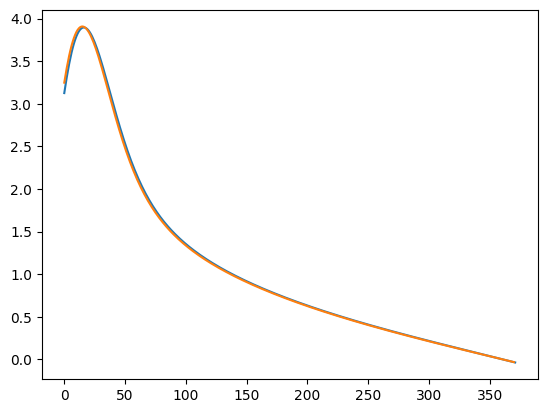

In [42]:
plt.plot(traj_pred[:,2])
plt.plot(traj_test_obs[L:-horizon,0,2])

In [43]:
k = 100
U_all = U.reshape(B*n_t, p*L).detach().cpu().numpy()
pca = PCA(n_components=k)
       # (B*n_t, k)
S_all = pca.fit_transform(U_all)                      # (B*n_t,k)
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

mu_u = torch.tensor(pca.mean_, device=U.device, dtype=U.dtype)           # (d_u,)
V_k  = torch.tensor(pca.components_, device=U.device, dtype=U.dtype)     # (k, d_u)

# 2) reshape latent sequence
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

# 3) build pairs
S_flat      = S_seq[:, :-1, :].reshape(B*(n_t-1), k)
S_next_flat = S_seq[:, 1:,  :].reshape(B*(n_t-1), k)

# 4) ridge solve for A
beta = 1e-5
G = S_flat.T @ S_flat
H = S_flat.T @ S_next_flat
A_T = torch.linalg.solve(G + beta*torch.eye(k, device=U.device, dtype=U.dtype), H)
A = A_T.T

In [44]:
traj_test_obs = traj_test[:, :, ::10]

o = traj_test_obs[:, 0, :]             # (T, p)
o_std = (o - mu.squeeze(0).squeeze(0)) / sd.squeeze(0).squeeze(0)   # (T,p)

In [45]:
T = o.shape[0]

t0 = L - 1
t1 = T - 1 - horizon          # IMPORTANT
t_vals = list(range(t0, t1 + 1))
n_t = len(t_vals)

U_test = torch.empty(n_t, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals):
    window = o_std[t-L+1:t+1, :]
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i, :] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T

A10 = torch.matrix_power(A, horizon)
S10_pred = S_test @ A10.T
U10_pred = mu_u + (S10_pred @ V_k)
o10_pred_std = U10_pred[:, :p]
mu_obs = mu.squeeze(0).squeeze(0)   # (p,)
sd_obs = sd.squeeze(0).squeeze(0)   # (p,)
o10_pred = mu_obs + sd_obs * o10_pred_std


t_tensor = torch.tensor(t_vals, device=o.device)
o_true_h = o[t_tensor + horizon, :]      # now always in-bounds
o_pers   = o[t_tensor, :]
mse      = ((o10_pred - o_true_h)**2).mean()
pers_mse = ((o_pers   - o_true_h)**2).mean()

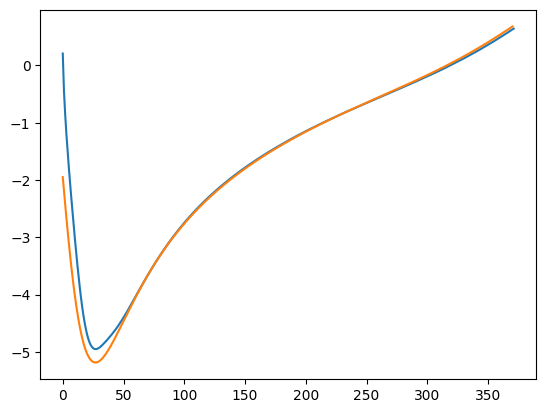

In [46]:
plt.plot(o10_pred[:,7])
plt.plot(traj_test_obs[L+horizon:,0,7])

In [47]:
S = S_seq[:, :-1, :].reshape(-1, k)

traj_obs = traj_ks[:, :, ::10]                    # (T,B,p)

S0   = S_seq[:, :-horizon, :].reshape(-1, k)
dS_h = (S_seq[:, horizon:, :] - S_seq[:, :-horizon, :]).reshape(-1, k)


# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


S_train = S0.reshape(-1, k)           # (B*(n_t-h), k)


O_seq = obs_std[t_vals, :, :]          # (n_t, B, p)
O_seq = O_seq.permute(1, 0, 2)         # (B, n_t, p)  to match S_seq shape
O = O_seq[:, :-1, :].reshape(-1, p)    # (B*(n_t-1), p)

In [48]:
M = S.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=S.device)
idx2 = torch.randint(0, M, (sample_size,), device=S.device)
d = torch.linalg.norm(S[idx1] - S[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
mvn = MultivariateNormal(torch.zeros(S.shape[1]),ell**-2*torch.eye(S.shape[1]))
Omega = torch.randn(P, S.shape[1], device=S.device, dtype=U_train.dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=S.device, dtype=U_train.dtype))

In [49]:
p

26

In [50]:
def build_W_f(S_train, dS, Omega, b,sigma = 1.0,P=512, lam=10**3):
        # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = dS.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        phi_i = phi(S_train[i], Omega, b, sigma, P)# (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, dS[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return W

def build_C_tilde(S_train, O, lam=10**3):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = O.shape[1]
    d = d_u+1
    

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        one = torch.ones(1, device=S_train.device, dtype=S_train.dtype)
        phi_i = torch.cat([S_train[i], one])
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, O[i])                      # (d,p_out)
    G /= n
    H /= n

    C_tilde = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return C_tilde

In [93]:
lam_f = 10**1
lam_g = 10**-5

W_h = build_W_f(S_train,dS_h,Omega,b,sigma=1.0,P=P,lam=lam_f)

In [94]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)   # (B,n_t,p)
O0 = O_seq[:, :-horizon, :].reshape(-1, p)           # aligns with S0

C_tilde = build_C_tilde(S0, O0, lam=lam_g)
C = C_tilde[:-1, :]
d = C_tilde[-1, :]

In [95]:
o = traj_test_obs[:,0,:]         # (T_test,p)
T_test = o.shape[0]
t0 = L - 1
t1 = T_test - 1 - horizon
t_vals_test = list(range(t0, t1+1))
n_test = len(t_vals_test)
U_test = torch.empty(n_test, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals_test):
    window = o_std[t-L+1:t+1, :]         # (L,p)
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i,:] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T         # (n_test,k)

In [96]:
def phi_batch(S, Omega, b, sigma=1.0, P=512):
    # S: (n,k), Omega: (P,k), b: (P,)
    Z = (Omega @ S.T).T + b           # (n,P)
    z = (2.0/P)**0.5 * torch.cos(Z)   # (n,P)
    return torch.cat([S, sigma*z], dim=1)  # (n,k+P

Phi0 = phi_batch(S_test, Omega, b, sigma, P)
dS_pred = Phi0 @ W_h
S_pred = S_test + dS_pred


o_pred_std = S_pred @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

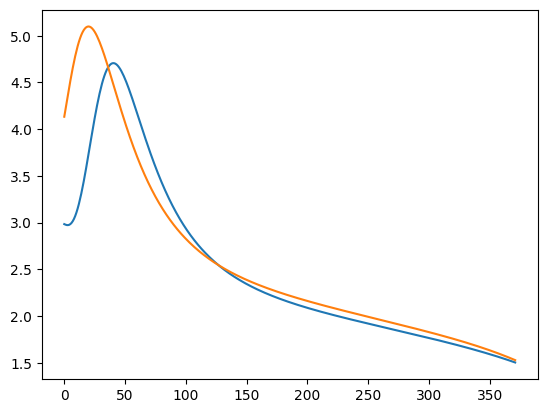

In [97]:
plt.plot(o_pred[:,5])
plt.plot(o_true[:,5])

In [98]:
def standardize_fit(X, eps=1e-6):
    """
    X: (n, d)
    returns: Xs, mean (1,d), std (1,d)
    """
    mean = X.mean(dim=0, keepdim=True)
    std  = X.std(dim=0, keepdim=True) + eps
    Xs = (X - mean) / std
    return Xs, mean, std

def standardize_apply(X, mean, std):
    return (X - mean) / std

def unstandardize_apply(Xs, mean, std):
    return Xs * std + mean

def phi_batch(S, Omega, b, sigma=1.0):
    """
    S: (n,k)
    Omega: (P,k)
    b: (P,)
    Returns: (n, k+P) = [S, sigma*z]
    """
    n, k = S.shape
    P = Omega.shape[0]
    Z = (S @ Omega.T) + b   # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)

def build_W_rff_ridge(S_in, Y_out, Omega, b, sigma=1.0, lam=1e-4):
    """
    S_in: (n,k) inputs
    Y_out: (n,k_out) targets
    W: (k+P, k_out)
    """
    Phi = phi_batch(S_in, Omega, b, sigma=sigma)  # (n, k+P)
    n = Phi.shape[0]
    G = (Phi.T @ Phi) / n
    H = (Phi.T @ Y_out) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W



def predict_direct_horizon_latent(S0, W_h, Omega, b, sigma=1.0):
    """
    S0: (n,k) (already standardized if that's what you trained on)
    returns dS_pred: (n,k)
    """
    Phi0 = phi_batch(S0, Omega, b, sigma=sigma)  # (n, k+P)
    return Phi0 @ W_h

In [99]:

# Standardize inputs and targets
S0s, S_mean, S_std = standardize_fit(S0)
dS_s, dS_mean, dS_std = standardize_fit(dS_h)

# Choose ell and sample Omega,b based on STANDARDIZED inputs
# (you can keep your median heuristic here)
# Omega: (P,k)
# b: (P,)

W_h = build_W_rff_ridge(S0s, dS_s, Omega, b, sigma=1.0, lam=lam_f)

# 1) standardize input latents using TRAIN stats
S_test0s = standardize_apply(S_test, S_mean, S_std)

# 2) predict standardized latent increment
dS_pred_s = predict_direct_horizon_latent(S_test0s, W_h, Omega, b, sigma=1.0)

# 3) unstandardize increment back to latent units
dS_pred = unstandardize_apply(dS_pred_s, dS_mean, dS_std)

# 4) form predicted latent at horizon
S_pred_h = S_test + dS_pred


o_pred_std = S_pred_h @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

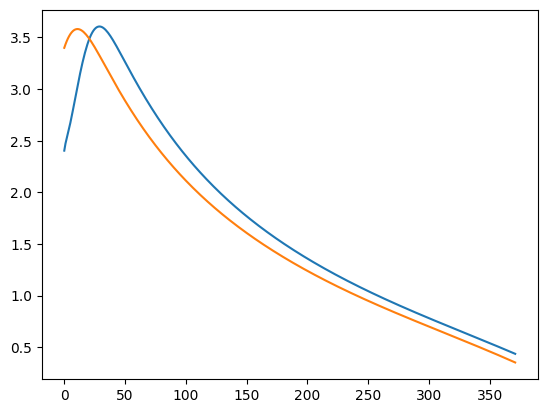

In [100]:
plt.plot(o_pred[:,3])
plt.plot(o_true[:,3])

In [101]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)     # (B, n_t, p)
S_dec = S_seq.reshape(B*n_t, k)                  # (B*n_t, k)
O_dec = O_seq.reshape(B*n_t, p)                  # (B*n_t, p)

In [102]:
def median_ell(X, sample_size=5000):
    n = X.shape[0]
    idx1 = torch.randint(0, n, (sample_size,), device=X.device)
    idx2 = torch.randint(0, n, (sample_size,), device=X.device)
    d = torch.linalg.norm(X[idx1] - X[idx2], dim=1)
    return d.median()

# optional: standardize S_dec before choosing ell
S_mean = S_dec.mean(dim=0, keepdim=True)
S_std  = S_dec.std(dim=0, keepdim=True) + 1e-6
S_dec_s = (S_dec - S_mean) / S_std

ell_o = median_ell(S_dec_s)
P_o = 256
Omega_o = torch.randn(P_o, k, device=S_dec.device, dtype=S_dec.dtype) / ell_o
b_o = 2*torch.pi*torch.rand(P_o, device=S_dec.device, dtype=S_dec.dtype)

In [103]:
def psi_batch(S, Omega, b, sigma=1.0):
    # S: (n,k), Omega: (P,k), b: (P,)
    n, k = S.shape
    P = Omega.shape[0]
    Z = S @ Omega.T + b              # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)   # (n, k+P)

def fit_rff_ridge(X_feat, Y, lam=1e-4):
    # X_feat: (n,d), Y: (n,p_out)
    n = X_feat.shape[0]
    G = (X_feat.T @ X_feat) / n
    H = (X_feat.T @ Y) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W

In [104]:
Psi = psi_batch(S_dec_s, Omega_o, b_o, sigma=1.0)  # (n, k+P_o)
W_o = fit_rff_ridge(Psi, O_dec, lam=lam_g)         # (k+P_o, p)

In [105]:
S_pred_s = (S_pred_h - S_mean) / S_std
o_pred_std = psi_batch(S_pred_s, Omega_o, b_o, sigma=1.0) @ W_o   # (n_test, p)

o_pred = mu_obs + sd_obs * o_pred_std


mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

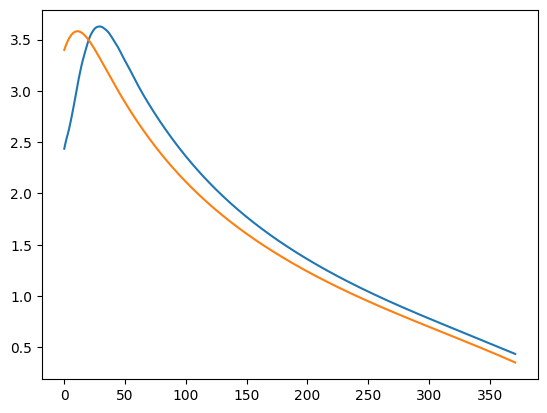

In [106]:
plt.plot(o_pred[:,3])
plt.plot(o_true[:,3])